# langfeat_teacher_check:dino.txt 能否按名字在我们的视角里找到物体

**目的**:路线 1(langfeat_v1)要把 dino.txt 的 patch 特征蒸馏到冻结 3DRAE token 上的一个头里。学生最多学到老师的水平,所以先测老师。这里不训练任何东西。

**做法**(脚本 `jepa3d/tools/check_teacher_grounding.py`,任务 13004)
- 数据:EmbodiedScan 验证集的 ScanNet 场景,229 个场景 × 3 个采样种子 = 687 个样本,每个样本 8 张带位姿的图。
- 对每个场景内唯一的物体:文本 "a photo of a <类别>" → 在 8 张图的全部 patch 里取与文本最相似的一个 → 量物体 3D 框中心到穿过该 patch 的射线的距离(米)。
- 参照:随机 patch(瞎指)和最优 patch(离中心最近的 patch)。
- 命中:射线距离 ≤ 0.5 m。

**事先定的判据**:视野内物体的射线距离中位数 ≤ 0.5 m;稀有类别不超过常见类别的 2 倍。

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

runs = {s: json.load(open(f"../results/dinotxt_{s}.json")) for s in ("224x308", "448x616")}
GROUPS = [("all", "全部物体"), ("in_view", "中心在视野内"), ("in_view_freq_200+", "视野内,训练集 200+ 次"),
          ("in_view_freq_20-199", "视野内,20–199 次"), ("in_view_freq_1-19", "视野内,1–19 次"),
          ("in_view_freq_unseen", "视野内,训练集没出现过")]

def cell(m, key, pct=False):
    v = m[key]
    if pct:
        return f'{100 * v["value"]:.1f}% [{100 * v["ci95"][0]:.1f}, {100 * v["ci95"][1]:.1f}]'
    return f'{v["value"]:.2f} [{v["ci95"][0]:.2f}, {v["ci95"][1]:.2f}]'

def table(size):
    m = runs[size]["metrics"]
    rows = []
    for g, label in GROUPS:
        rows.append({"分组": label, "物体数": m[f"{g}/teacher_m"]["n"],
                     "dino.txt 中位数 (m)": cell(m, f"{g}/teacher_m"), "随机 (m)": cell(m, f"{g}/random_m"),
                     "最优 (m)": cell(m, f"{g}/oracle_m"), "dino.txt 命中率": cell(m, f"{g}/teacher_hit_acc", True),
                     "随机命中率": cell(m, f"{g}/random_hit_acc", True)})
    return pd.DataFrame(rows)

## 1. 输入 224×308(与 3DRAE 的输入同尺寸)

方括号里是按场景重采样的 95% 置信区间。

In [2]:
table("224x308")

,分组,物体数,dino.txt 中位数 (m),随机 (m),最优 (m),dino.txt 命中率,随机命中率
0,全部物体,6474,"0.73 [0.69, 0.81]","1.61 [1.55, 1.70]","0.04 [0.03, 0.04]","37.2% [35.1, 39.7]","5.9% [5.4, 6.4]"
1,中心在视野内,4949,"0.63 [0.58, 0.70]","1.59 [1.52, 1.66]","0.03 [0.03, 0.03]","42.8% [40.4, 45.2]","6.8% [6.3, 7.3]"
2,"视野内,训练集 200+ 次",996,"0.52 [0.48, 0.57]","1.54 [1.46, 1.63]","0.03 [0.03, 0.03]","48.3% [43.6, 52.8]","7.0% [6.1, 7.9]"
3,"视野内,20–199 次",3516,"0.62 [0.56, 0.69]","1.61 [1.54, 1.66]","0.03 [0.03, 0.03]","43.5% [40.5, 46.5]","6.7% [6.2, 7.1]"
4,"视野内,1–19 次",408,"1.16 [0.97, 1.29]","1.59 [1.45, 1.84]","0.03 [0.02, 0.03]","26.2% [19.7, 32.4]","7.4% [6.1, 9.5]"
5,"视野内,训练集没出现过",29,"2.24 [1.55, 2.73]","2.03 [1.66, 2.63]","0.03 [0.02, 0.05]","3.4% [0.0, 11.1]","4.6% [3.4, 6.0]"


## 2. 输入 448×616

In [3]:
table("448x616")

,分组,物体数,dino.txt 中位数 (m),随机 (m),最优 (m),dino.txt 命中率,随机命中率
0,全部物体,6474,"0.71 [0.66, 0.76]","1.61 [1.55, 1.70]","0.02 [0.02, 0.02]","37.9% [35.5, 40.2]","5.9% [5.4, 6.4]"
1,中心在视野内,4949,"0.60 [0.56, 0.66]","1.59 [1.52, 1.66]","0.01 [0.01, 0.02]","43.6% [40.9, 45.9]","6.8% [6.3, 7.3]"
2,"视野内,训练集 200+ 次",996,"0.50 [0.46, 0.55]","1.54 [1.46, 1.63]","0.01 [0.01, 0.02]","50.4% [45.6, 54.6]","7.0% [6.1, 7.9]"
3,"视野内,20–199 次",3516,"0.61 [0.56, 0.67]","1.61 [1.53, 1.66]","0.01 [0.01, 0.01]","43.9% [40.9, 46.9]","6.7% [6.2, 7.1]"
4,"视野内,1–19 次",408,"1.09 [0.88, 1.26]","1.59 [1.45, 1.84]","0.01 [0.01, 0.02]","27.2% [19.9, 33.2]","7.4% [6.1, 9.5]"
5,"视野内,训练集没出现过",29,"1.94 [1.36, 2.24]","2.03 [1.66, 2.63]","0.02 [0.02, 0.02]","3.4% [0.0, 11.1]","4.6% [3.4, 6.0]"


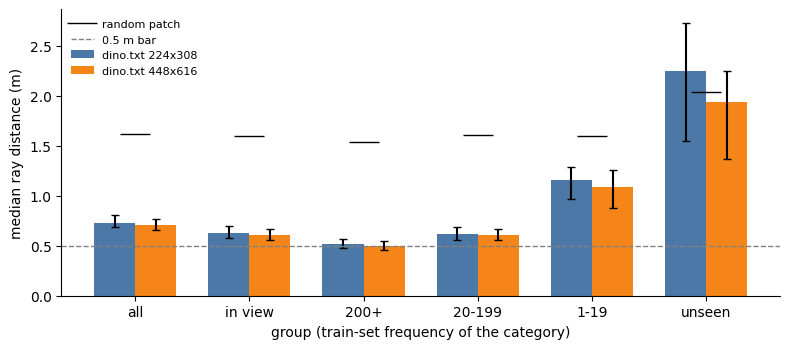

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = ["all", "in view", "200+", "20-199", "1-19", "unseen"]
x = range(len(GROUPS))
for i, (size, color) in enumerate((("224x308", "#4c78a8"), ("448x616", "#f58518"))):
    m = runs[size]["metrics"]
    vals = [m[f"{g}/teacher_m"]["value"] for g, _ in GROUPS]
    lo = [v - m[f"{g}/teacher_m"]["ci95"][0] for v, (g, _) in zip(vals, GROUPS)]
    hi = [m[f"{g}/teacher_m"]["ci95"][1] - v for v, (g, _) in zip(vals, GROUPS)]
    ax.bar([k + (i - 0.5) * 0.36 for k in x], vals, 0.36, yerr=[lo, hi], capsize=3, color=color, label=f"dino.txt {size}")
m = runs["224x308"]["metrics"]
ax.plot(list(x), [m[f"{g}/random_m"]["value"] for g, _ in GROUPS], "k_", markersize=22, label="random patch")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="0.5 m bar")
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylabel("median ray distance (m)"); ax.set_xlabel("group (train-set frequency of the category)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3. 结论

1. **老师有明显信号,但没达到判据。** 视野内物体:0.63 m(224×308)、0.60 m(448×616),随机是 1.60 m,判据是 ≤ 0.5 m。命中率 43–44%,随机 7%。
2. **分辨率几乎没用。** 448×616 只比 224×308 好 0.02 m,两者置信区间重叠。蒸馏时用 224×308 即可。
3. **老师对冷门类别明显更差。** 训练集 200+ 次的类别 0.50–0.52 m,1–19 次的类别 1.09–1.16 m,约 2.2 倍,略超过 2 倍的判据。训练集没出现过的类别(只有 29 个物体)在随机水平。
4. **第 3 点削弱了路线 1 的主要理由。** dino.txt 没有用过我们的标注,它在冷门类别上仍然差,所以蒸馏不会自动解决长尾。原因没有查:可能是这些类别名太细,也可能是这些物体本身小、更难指中。

## 4. 这个检查的局限

- **判据偏严。** 量的是到框中心的距离。大物体(床、桌子、柜子)上最相似的 patch 落在物体边缘时,也会算成 0.5 m 以外。更公平的量法是「射线是否穿过 3D 框」,这次没算。
- **只取了一个 patch。** 蒸馏用的是整张相似度图,不是 argmax。一个 patch 指错不代表整张图没信息。
- **只试了一个提示模板**("a photo of a ..."),没有试多模板平均。
- **物体只取场景内唯一的类别**,与 probe 的口径一致。
- 射线距离不含深度误差,和 probe 的 3D 位置误差(0.95 m)不能直接比。